# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Muhammad Mubashir Shafique
- **Roll No:** 023-24-0235
- **Section:** G
- **Date:** 12 November 2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

print("Slide 16:", predict([0.6, 0.8], [2, 3], -2), "(expected 1)")
w17, b17 = [1, -0.5], 0.5
out17 = [predict(w17, x, b17) for x in ([1, 1], [2, 1], [0, 3])]
print("Slide 17:", out17, "(expected [1, 1, 0])")


Slide 16: 1 (expected 1)
Slide 17: [1, 1, 0] (expected [1, 1, 0])


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
data = [(0, 0, 0), (0, 1, 0), (1, 0, 0), (1, 1, 1)]
w, b, eta = np.array([0.2, -0.1]), 0.0, 0.1
mistakes = 0
for x1, x2, y in data:
    x = np.array([x1, x2])
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)
    e = y - y_hat
    if e != 0:
        mistakes += 1
    w = w + eta * e * x
    b = b + eta * e
    print(f"x=({x1},{x2}) y={y} | z={z:.2f} y_hat={y_hat} e={e:+d} | w=[{w[0]:.2f}, {w[1]:.2f}] b={b:.2f}")
print(f"\nFinal w = {np.round(w, 2)}, b = {b:.2f}, mistakes = {mistakes}")
print("Converged!" if mistakes == 0 else "Keep training.")


x=(0,0) y=0 | z=0.00 y_hat=1 e=-1 | w=[0.20, -0.10] b=-0.10
x=(0,1) y=0 | z=-0.20 y_hat=0 e=+0 | w=[0.20, -0.10] b=-0.10
x=(1,0) y=0 | z=0.10 y_hat=1 e=-1 | w=[0.10, -0.10] b=-0.20
x=(1,1) y=1 | z=-0.20 y_hat=0 e=+1 | w=[0.20, 0.00] b=-0.10

Final w = [0.2 0. ], b = -0.10, mistakes = 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    w, b = np.zeros(X.shape[1]), 0.0
    mistakes = []
    for _ in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, b)
            if e != 0:
                w = w + eta * e * xi
                b = b + eta * e
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])
w_or, b_or, mist_or = train_perceptron(X_or, y_or)
print("OR gate -> w =", np.round(w_or, 3), "| b =", round(b_or, 3))
print("Mistakes per epoch:", mist_or)


OR gate -> w = [0.1 0.1] | b = -0.1
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

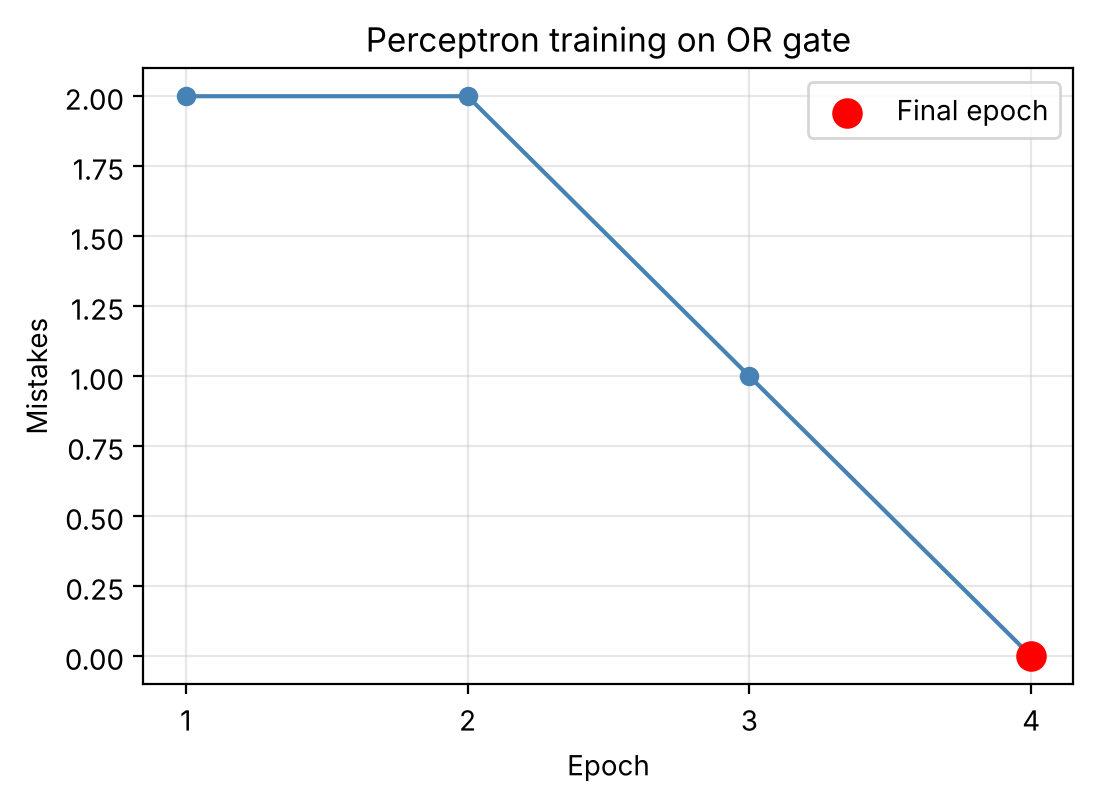

In [5]:
# Task 2.2
epochs = np.arange(1, len(mist_or) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, mist_or, marker="o", color="steelblue")
plt.scatter(epochs[-1], mist_or[-1], color="red", s=100, zorder=3, label="Final epoch")
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Interpretation:** The number of mistakes falls from 2 to 2 to 1 to 0 over four epochs, so the perceptron converges on the OR gate at epoch 4 (red dot) and stops, as the convergence theorem guarantees for linearly separable data.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

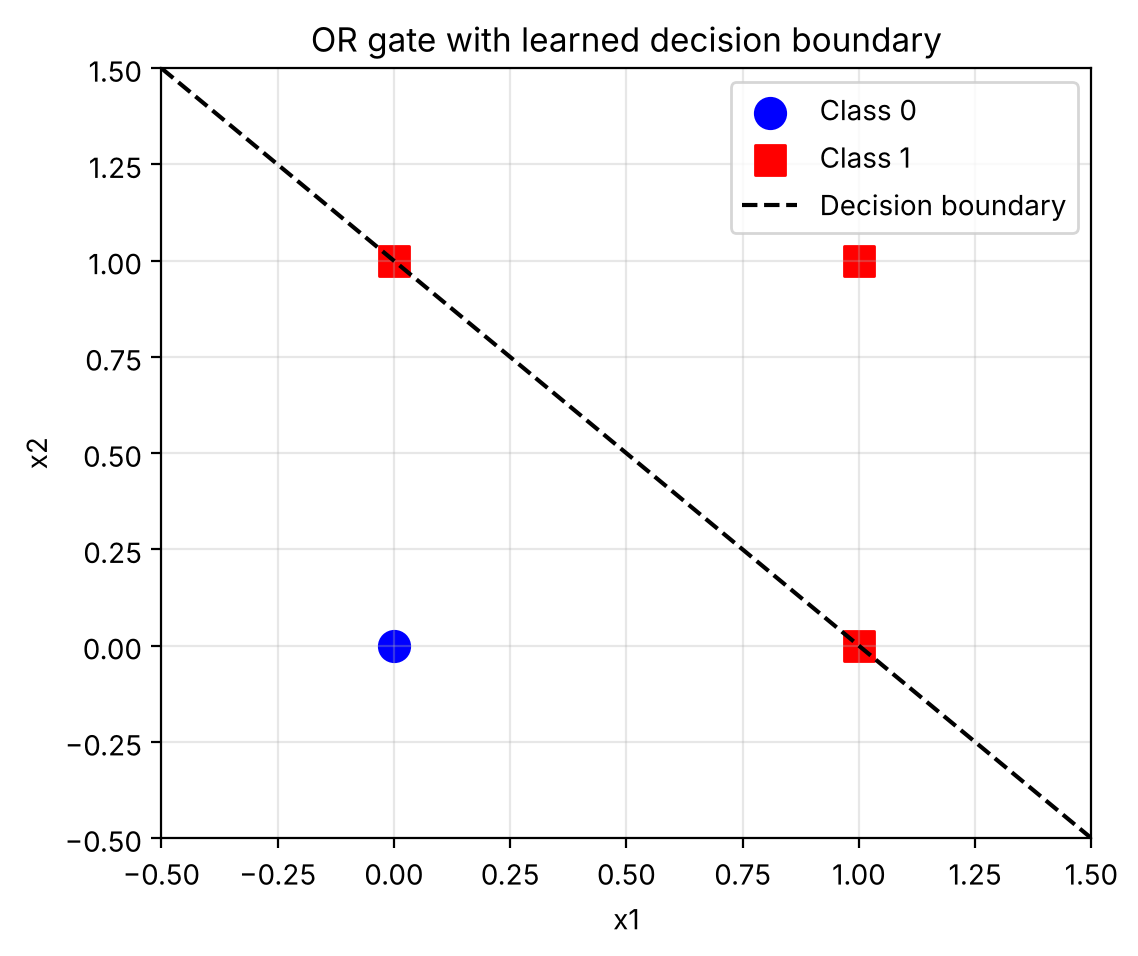

w = [0.1 0.1] b = -0.1


In [6]:
# Task 3.1
def plot_boundary(ax, w, b, xlim=(-0.5, 1.5), **kwargs):
    kwargs.setdefault("color", "black")
    kwargs.setdefault("linestyle", "--")
    kwargs.setdefault("label", "Decision boundary")
    w1, w2 = w[0], w[1]
    if w2 != 0:
        x1 = np.linspace(xlim[0], xlim[1], 100)
        ax.plot(x1, -(w1 / w2) * x1 - b / w2, **kwargs)
    elif w1 != 0:
        ax.axvline(-b / w1, **kwargs)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(*X_or[y_or == 0].T, c="blue", marker="o", s=120, label="Class 0")
ax.scatter(*X_or[y_or == 1].T, c="red", marker="s", s=120, label="Class 1")
plot_boundary(ax, w_or, b_or)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_title("OR gate with learned decision boundary")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print("w =", np.round(w_or, 3), "b =", round(b_or, 3))


**Interpretation:** With w = [0.1, 0.1] and b = −0.1 the boundary is the line x₁ + x₂ = 1, which separates (0,0) from the other three points. ŷ = 1 on the upper-right side of the line (x₁ + x₂ ≥ 1), and the points (0,1) and (1,0) lie exactly on it (z = 0 gives ŷ = 1).

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias   : w=[0.1 0.1], b=-0.200, epochs=4, final mistakes=0
Without bias: w=[0.1 0. ], b=0.000, epochs=100, final mistakes=2
No-bias version converged: False


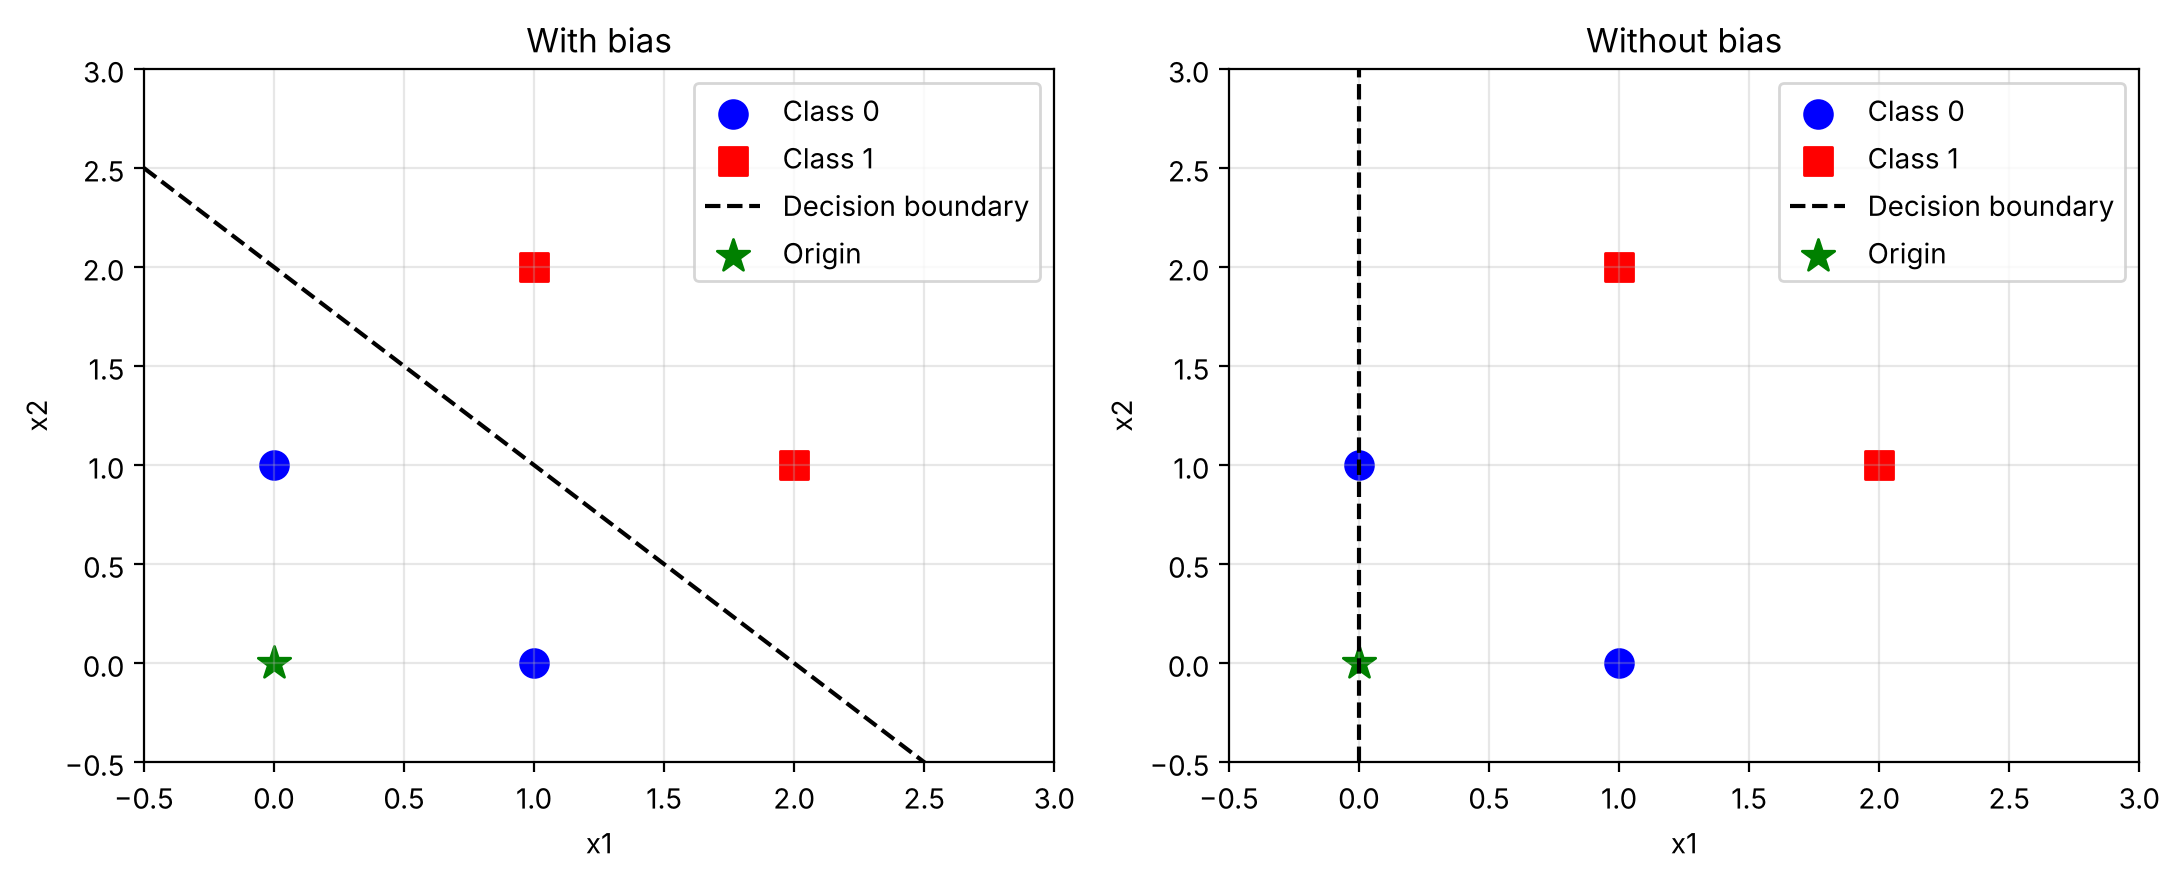

In [7]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    w, b = np.zeros(X.shape[1]), 0.0
    mistakes = []
    for _ in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, b)
            if e != 0:
                w = w + eta * e * xi
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

X32 = np.array([[1, 0], [0, 1], [2, 1], [1, 2]])
y32 = np.array([0, 0, 1, 1])
w_b, b_b, m_b = train_perceptron(X32, y32)
w_n, b_n, m_n = train_perceptron_nobias(X32, y32)
print(f"With bias   : w={np.round(w_b, 3)}, b={b_b:.3f}, epochs={len(m_b)}, final mistakes={m_b[-1]}")
print(f"Without bias: w={np.round(w_n, 3)}, b={b_n:.3f}, epochs={len(m_n)}, final mistakes={m_n[-1]}")
print("No-bias version converged:", m_n[-1] == 0)

plt.figure(figsize=(11, 4.5))
for k, (title, w_, b_) in enumerate([("With bias", w_b, b_b), ("Without bias", w_n, b_n)], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(*X32[y32 == 0].T, c="blue", marker="o", s=100, label="Class 0")
    ax.scatter(*X32[y32 == 1].T, c="red", marker="s", s=100, label="Class 1")
    plot_boundary(ax, w_, b_, xlim=(-0.5, 3))
    ax.scatter(0, 0, c="green", marker="*", s=150, label="Origin")
    ax.set_xlim(-0.5, 3)
    ax.set_ylim(-0.5, 3)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** The version with bias converged in 4 epochs (boundary x₁ + x₂ = 2), but the no-bias version did not converge: after 100 epochs it still makes 2 mistakes. Removing the bias forces the boundary through the origin (here a vertical line at x₁ = 0), and no line through the origin separates these two classes.

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epochs run: 100
Final mistakes: 4
w = [-0.1  0. ] | b = 0.0
Mistake history (first 12): [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


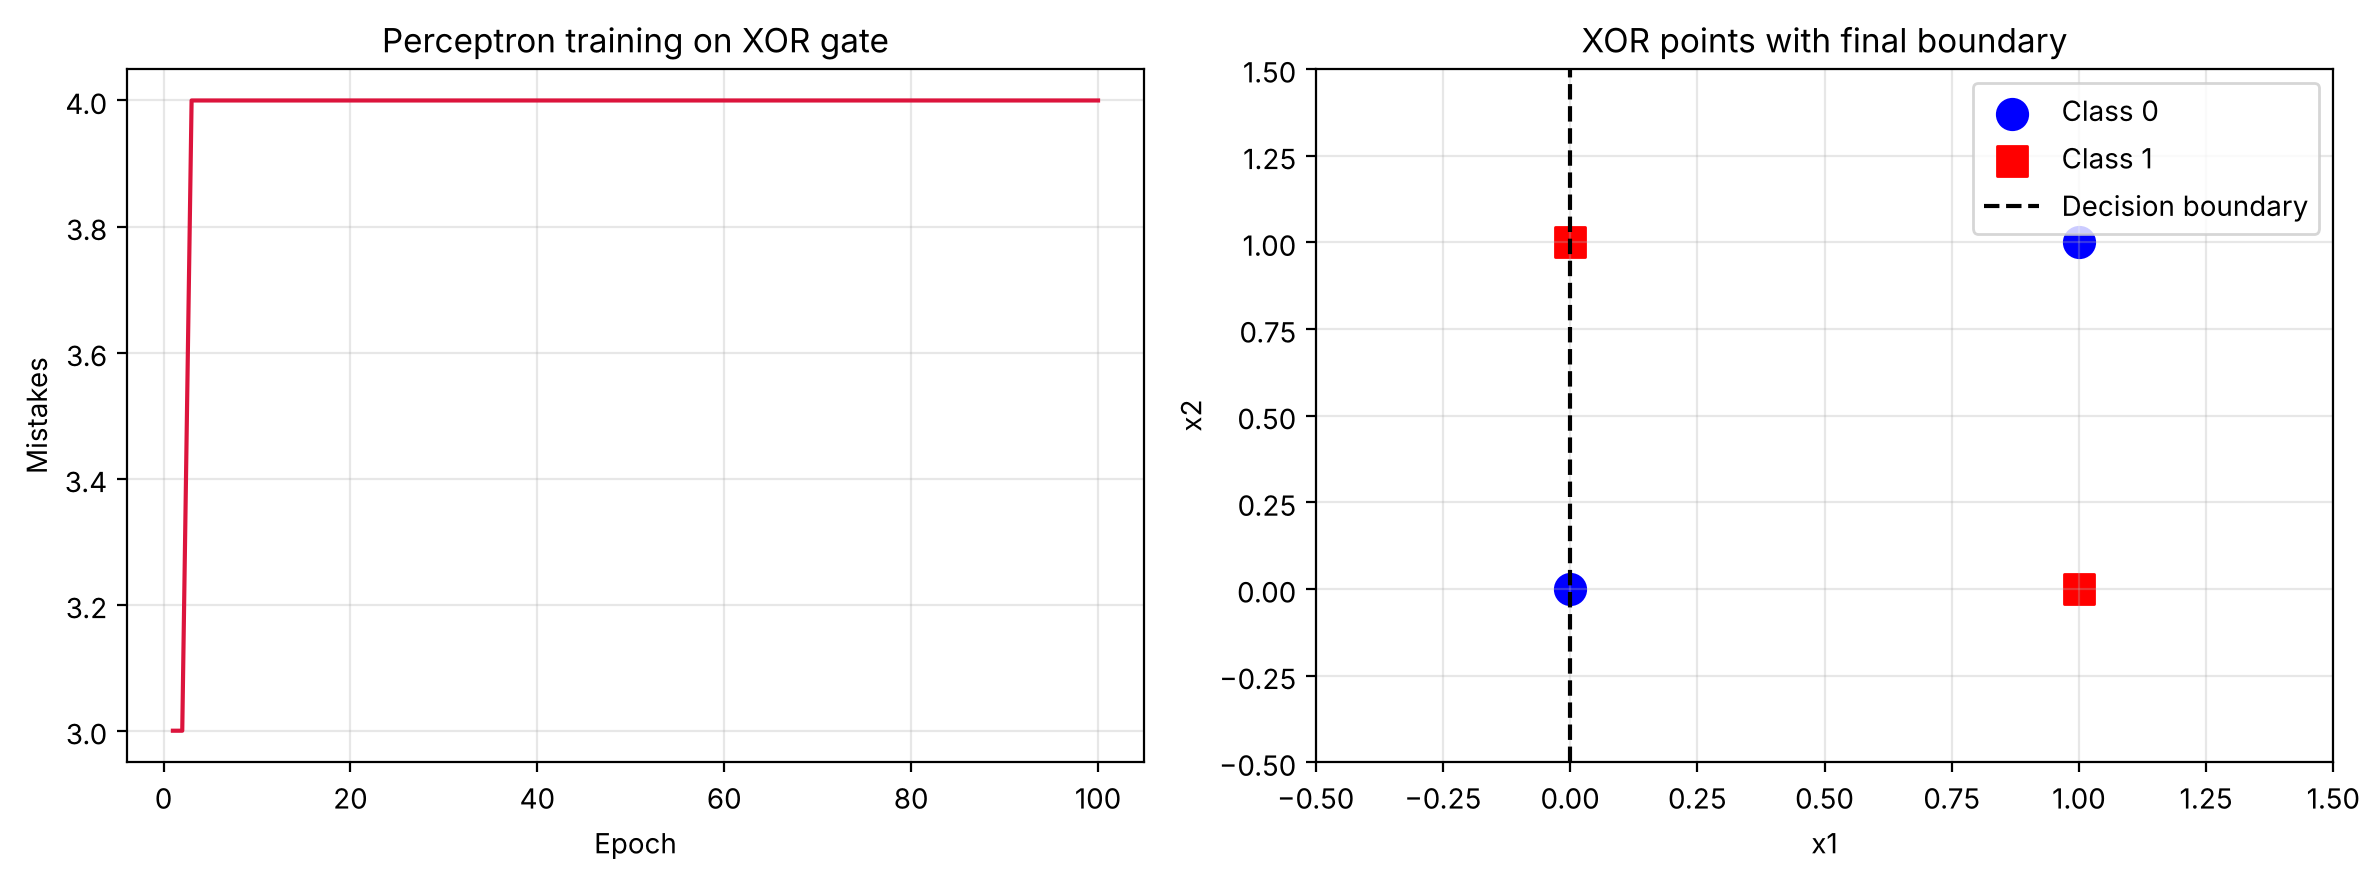

In [8]:
# Task 4.1
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
w_x, b_x, m_x = train_perceptron(X_xor, y_xor, max_epochs=100)
print("Epochs run:", len(m_x))
print("Final mistakes:", m_x[-1])
print("w =", np.round(w_x, 3), "| b =", round(b_x, 3))
print("Mistake history (first 12):", m_x[:12])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(range(1, len(m_x) + 1), m_x, color="crimson")
axes[0].set_title("Perceptron training on XOR gate")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mistakes")
axes[0].grid(alpha=0.3)

axes[1].scatter(*X_xor[y_xor == 0].T, c="blue", marker="o", s=120, label="Class 0")
axes[1].scatter(*X_xor[y_xor == 1].T, c="red", marker="s", s=120, label="Class 1")
plot_boundary(axes[1], w_x, b_x)
axes[1].set_xlim(-0.5, 1.5)
axes[1].set_ylim(-0.5, 1.5)
axes[1].set_title("XOR points with final boundary")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** The perceptron never reaches zero mistakes on XOR: it makes 3 mistakes in each of the first 2 epochs, then stays stuck at 4 mistakes per epoch until epoch 100, and ends with w = [−0.1, 0], b = 0. XOR is not linearly separable, so no single straight line can put (0,1) and (1,0) on one side and (0,0) and (1,1) on the other, and the weight updates just cycle without ever fixing all four points.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    return (np.dot(w, [0, 0]) + b < 0 and
            np.dot(w, [0, 1]) + b >= 0 and
            np.dot(w, [1, 0]) + b >= 0 and
            np.dot(w, [1, 1]) + b < 0)

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)
passing = [(W[i, 0], W[i, 1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]
print("Triples tested:", 10000)
print("Triples that satisfy XOR:", len(passing))
print("No solution found" if not passing else f"First passing triple: {passing[0]}")


Triples tested: 10000
Triples that satisfy XOR: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X5 = iris.data[:, (2, 3)]
y5 = (iris.target == 0).astype(int)
X5_tr, X5_te, y5_tr, y5_te = train_test_split(X5, y5, test_size=0.3, random_state=42, stratify=y5)

clf5 = Perceptron(random_state=42)
clf5.fit(X5_tr, y5_tr)
pred5 = clf5.predict(X5_te)

print("Accuracy:", accuracy_score(y5_te, pred5))
print("\nConfusion matrix:\n", confusion_matrix(y5_te, pred5))
print("\nClassification report:\n", classification_report(y5_te, pred5, target_names=["Rest", "Setosa"]))
print("coef_     :", clf5.coef_)
print("intercept_:", clf5.intercept_)


Accuracy: 1.0

Confusion matrix:
 [[30  0]
 [ 0 15]]

Classification report:
               precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_     : [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** The model reaches accuracy 1.0 with a perfect confusion matrix (30 Rest and 15 Setosa test points all correct), because Setosa is linearly separable from the other species using petal features. `coef_` = [−1.3, −2.2] is the weight vector w and `intercept_` = 4.0 is the bias b from Part 1.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

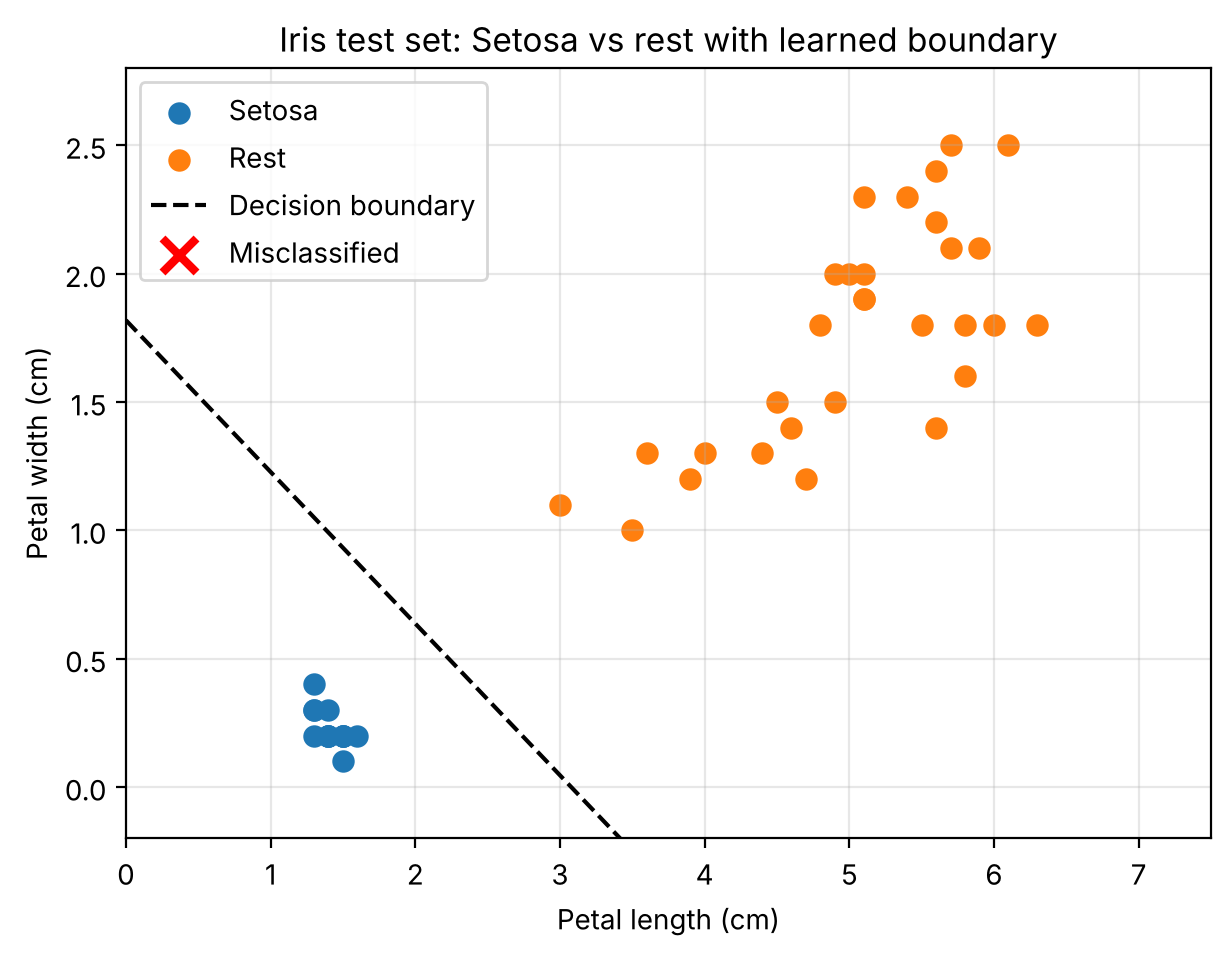

Misclassified test points: 0 of 45


In [11]:
# Task 5.2
w5, b5 = clf5.coef_[0], clf5.intercept_[0]
wrong = pred5 != y5_te

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(*X5_te[y5_te == 1].T, c="tab:blue", s=50, label="Setosa")
ax.scatter(*X5_te[y5_te == 0].T, c="tab:orange", s=50, label="Rest")
plot_boundary(ax, w5, b5, xlim=(0, 7.5))
ax.scatter(*X5_te[wrong].T, c="red", marker="x", s=150, linewidths=3, label="Misclassified", zorder=5)
ax.set_xlim(0, 7.5)
ax.set_ylim(-0.2, 2.8)
ax.set_title("Iris test set: Setosa vs rest with learned boundary")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print("Misclassified test points:", int(wrong.sum()), "of", len(y5_te))


**Interpretation:** 0 of the 45 test points are misclassified, so there are no red crosses. The boundary is a straight line because it is the set of points where w·x + b = 0, which is linear in the two features.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
rows = []
preds = {}
print(f"{'eta0':>8} | {'accuracy':>8} | {'n_iter_':>7} | coef_")
print("-" * 60)
for eta0 in (0.001, 0.1, 10.0):
    m = Perceptron(random_state=42, eta0=eta0).fit(X5_tr, y5_tr)
    preds[eta0] = m.predict(X5_te)
    print(f"{eta0:>8} | {accuracy_score(y5_te, preds[eta0]):>8.3f} | {m.n_iter_:>7} | {np.round(m.coef_[0], 4)}  (intercept {np.round(m.intercept_[0], 4)})")
keys = list(preds)
print("\nPredictions identical across all eta0:",
      all(np.array_equal(preds[keys[0]], preds[k]) for k in keys[1:]))


    eta0 | accuracy | n_iter_ | coef_
------------------------------------------------------------
   0.001 |    1.000 |       6 | [-0.0013 -0.0022]  (intercept 0.004)
     0.1 |    1.000 |       7 | [-0.13 -0.22]  (intercept 0.4)
    10.0 |    1.000 |       7 | [-13. -22.]  (intercept 40.0)

Predictions identical across all eta0: True


**Interpretation:** The predictions do not change: all three learning rates give accuracy 1.0 and identical test predictions. Because training starts from w = 0 and the update is η·e·x, changing η only rescales every weight and the bias by the same factor (coef_ is about 100 times larger for each 100-fold increase in η0), so the sign of z and therefore the boundary stay the same.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X6, y6 = iris.data, iris.target
X6_tr, X6_te, y6_tr, y6_te = train_test_split(X6, y6, test_size=0.3, random_state=42, stratify=y6)

clf6 = Perceptron(random_state=42, max_iter=1000)
clf6.fit(X6_tr, y6_tr)
pred6 = clf6.predict(X6_te)

print("Classification report:\n", classification_report(y6_te, pred6, target_names=iris.target_names, zero_division=0))
print("Confusion matrix:\n", confusion_matrix(y6_te, pred6))
print("coef_.shape:", clf6.coef_.shape)


Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)


**Interpretation:** Accuracy is only 0.667 and macro-F1 is 0.55. Each row of `coef_` (shape 3×4) holds the four weights of one one-vs-rest perceptron for one class. Versicolor is the hardest class (recall 0.00): 14 of its 15 test flowers were predicted as Setosa and 1 as Virginica, because the middle class cannot be separated from the other two by a single straight line.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
lr = LogisticRegression(random_state=42, max_iter=200)
lr.fit(X6_tr, y6_tr)
pred_lr = lr.predict(X6_te)

print(f"{'Model':<20} | {'Accuracy':>8} | {'Macro-F1':>8}")
print("-" * 44)
for name, p in [("Perceptron", pred6), ("Logistic Regression", pred_lr)]:
    print(f"{name:<20} | {accuracy_score(y6_te, p):>8.3f} | {f1_score(y6_te, p, average='macro'):>8.3f}")


Model                | Accuracy | Macro-F1
--------------------------------------------
Perceptron           |    0.667 |    0.550
Logistic Regression  |    0.933 |    0.933


**Interpretation:** Logistic regression clearly wins, with accuracy 0.933 and macro-F1 0.933 against 0.667 and 0.550 for the perceptron. Its smooth sigmoid has a gradient that is never exactly zero, so every sample (not only the mistakes) shapes the weights and it settles on a good compromise when classes overlap, while the step function only says right or wrong and keeps updating without converging.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**Answer:**
- z = (0.5)(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = **0.1**, so ŷ = step(0.1) = **1**
- e = y − ŷ = 0 − 1 = **−1** (a mistake, so we update)
- w₁ = 0.5 + 0.1·(−1)·1 = **0.4**
- w₂ = −0.3 + 0.1·(−1)·2 = **−0.5**
- b = 0.2 + 0.1·(−1) = **0.1**

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Answer:** The boundary is where z = 0: **0.3x₁ + 0.2x₂ − 0.4 = 0**, i.e. x₂ = −1.5x₁ + 2.
For (1, 1): z = 0.3 + 0.2 − 0.4 = 0.1 > 0, so the point lies on the **positive side** of the boundary and **ŷ = 1**, which is correct for AND.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

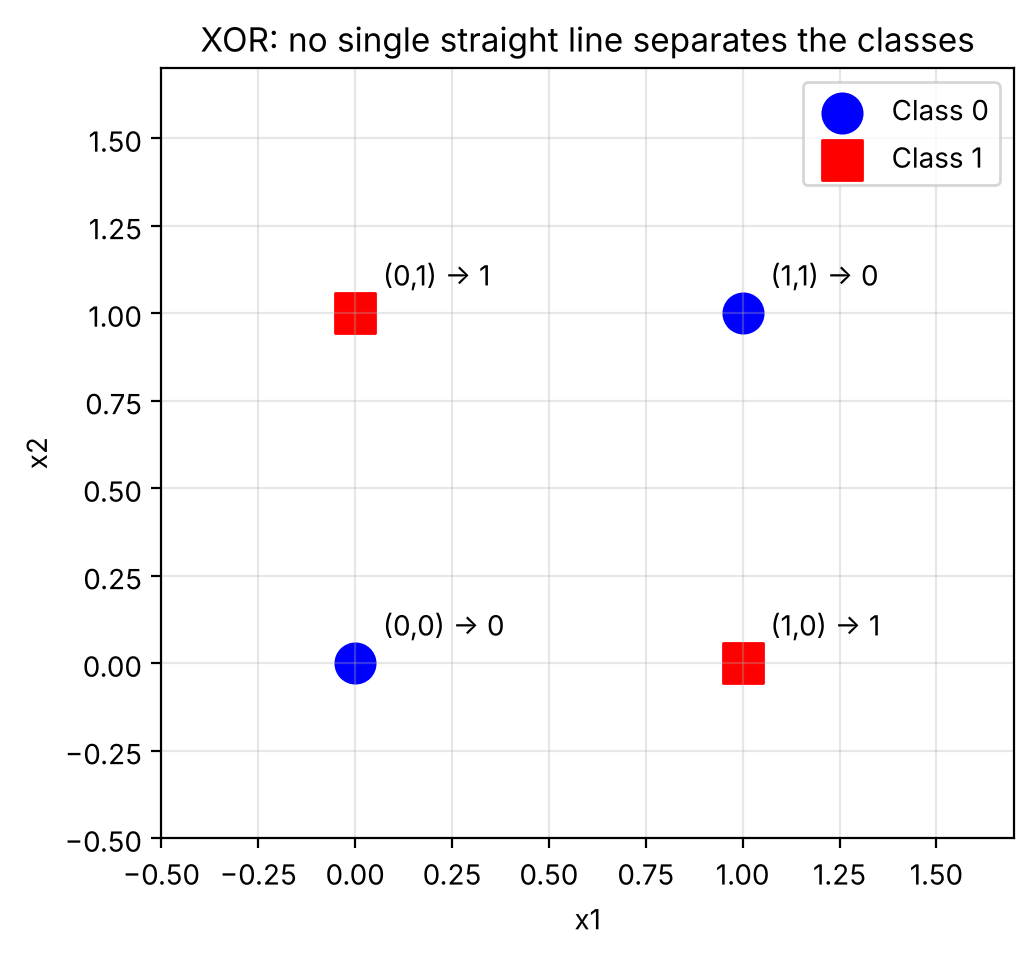

In [15]:
# Q3 (b)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(*X_xor[y_xor == 0].T, c="blue", marker="o", s=200, label="Class 0")
ax.scatter(*X_xor[y_xor == 1].T, c="red", marker="s", s=200, label="Class 1")
for (px, py), lab in zip(X_xor, y_xor):
    ax.annotate(f"({px},{py}) -> {lab}", (px, py), textcoords="offset points", xytext=(10, 10))
ax.set_xlim(-0.5, 1.7)
ax.set_ylim(-0.5, 1.7)
ax.set_title("XOR: no single straight line separates the classes")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


**Answer:**

**(a)** The four XOR constraints are:
1. (0,0) → 0: b < 0
2. (0,1) → 1: w₂ + b ≥ 0
3. (1,0) → 1: w₁ + b ≥ 0
4. (1,1) → 0: w₁ + w₂ + b < 0

Adding (2) and (3) gives w₁ + w₂ + 2b ≥ 0, so w₁ + w₂ + b ≥ −b. From (1), −b > 0, so w₁ + w₂ + b > 0, which contradicts (4). Therefore no (w₁, w₂, b) satisfies all four.

**(b)** The plot above shows the class-1 points (0,1) and (1,0) on one diagonal and the class-0 points (0,0) and (1,1) on the other; any straight line that separates one pair of diagonal points cuts through or leaves out the other.

**(c)** Add a hidden layer, i.e. use a multi-layer perceptron (for example two hidden units computing OR and NAND, combined by an AND output unit).

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [16]:
# Q4
def run_iris_binary(features):
    X = iris.data[:, features]
    y = (iris.target == 0).astype(int)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    m = Perceptron(random_state=42).fit(Xtr, ytr)
    p = m.predict(Xte)
    return accuracy_score(yte, p), f1_score(yte, p, average="macro"), m

print(f"{'Features':<12} | {'Accuracy':>8} | {'Macro-F1':>8} | {'n_iter_':>7}")
print("-" * 48)
for feats in [(2, 3), (0, 2, 3)]:
    acc, f1m, m = run_iris_binary(list(feats))
    print(f"{str(feats):<12} | {acc:>8.3f} | {f1m:>8.3f} | {m.n_iter_:>7}")
print("\ncoef_ with (0, 2, 3):", np.round(m.coef_[0], 3), "| intercept_:", np.round(m.intercept_[0], 3))


Features     | Accuracy | Macro-F1 | n_iter_
------------------------------------------------
(2, 3)       |    1.000 |    1.000 |       7
(0, 2, 3)    |    1.000 |    1.000 |       7

coef_ with (0, 2, 3): [ 4.5 -8.7 -4.1] | intercept_: 2.0


**Analysis:**

| Features | Accuracy | Macro-F1 |
|---|---|---|
| (2, 3) petal only | 1.000 | 1.000 |
| (0, 2, 3) with sepal length | 1.000 | 1.000 |

The extra feature does **not** help, because there is nothing left to improve: the petal features alone already give a perfect 1.000 accuracy and 1.000 macro-F1 on the test set, and adding sepal length gives exactly the same numbers (and the same n_iter_ = 7). Setosa is linearly separable from the other species using petals only, so sepal length is redundant for this binary task.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Model          | Test acc | Epochs | w                        | b
---------------------------------------------------------------------------
Hand-built     |    0.817 |    100 | [ 0.307 -0.256]          | 0.200
sklearn        |    0.667 |      6 | [0.228 0.058]            | 0.200
Hand-built final-epoch mistakes: 33


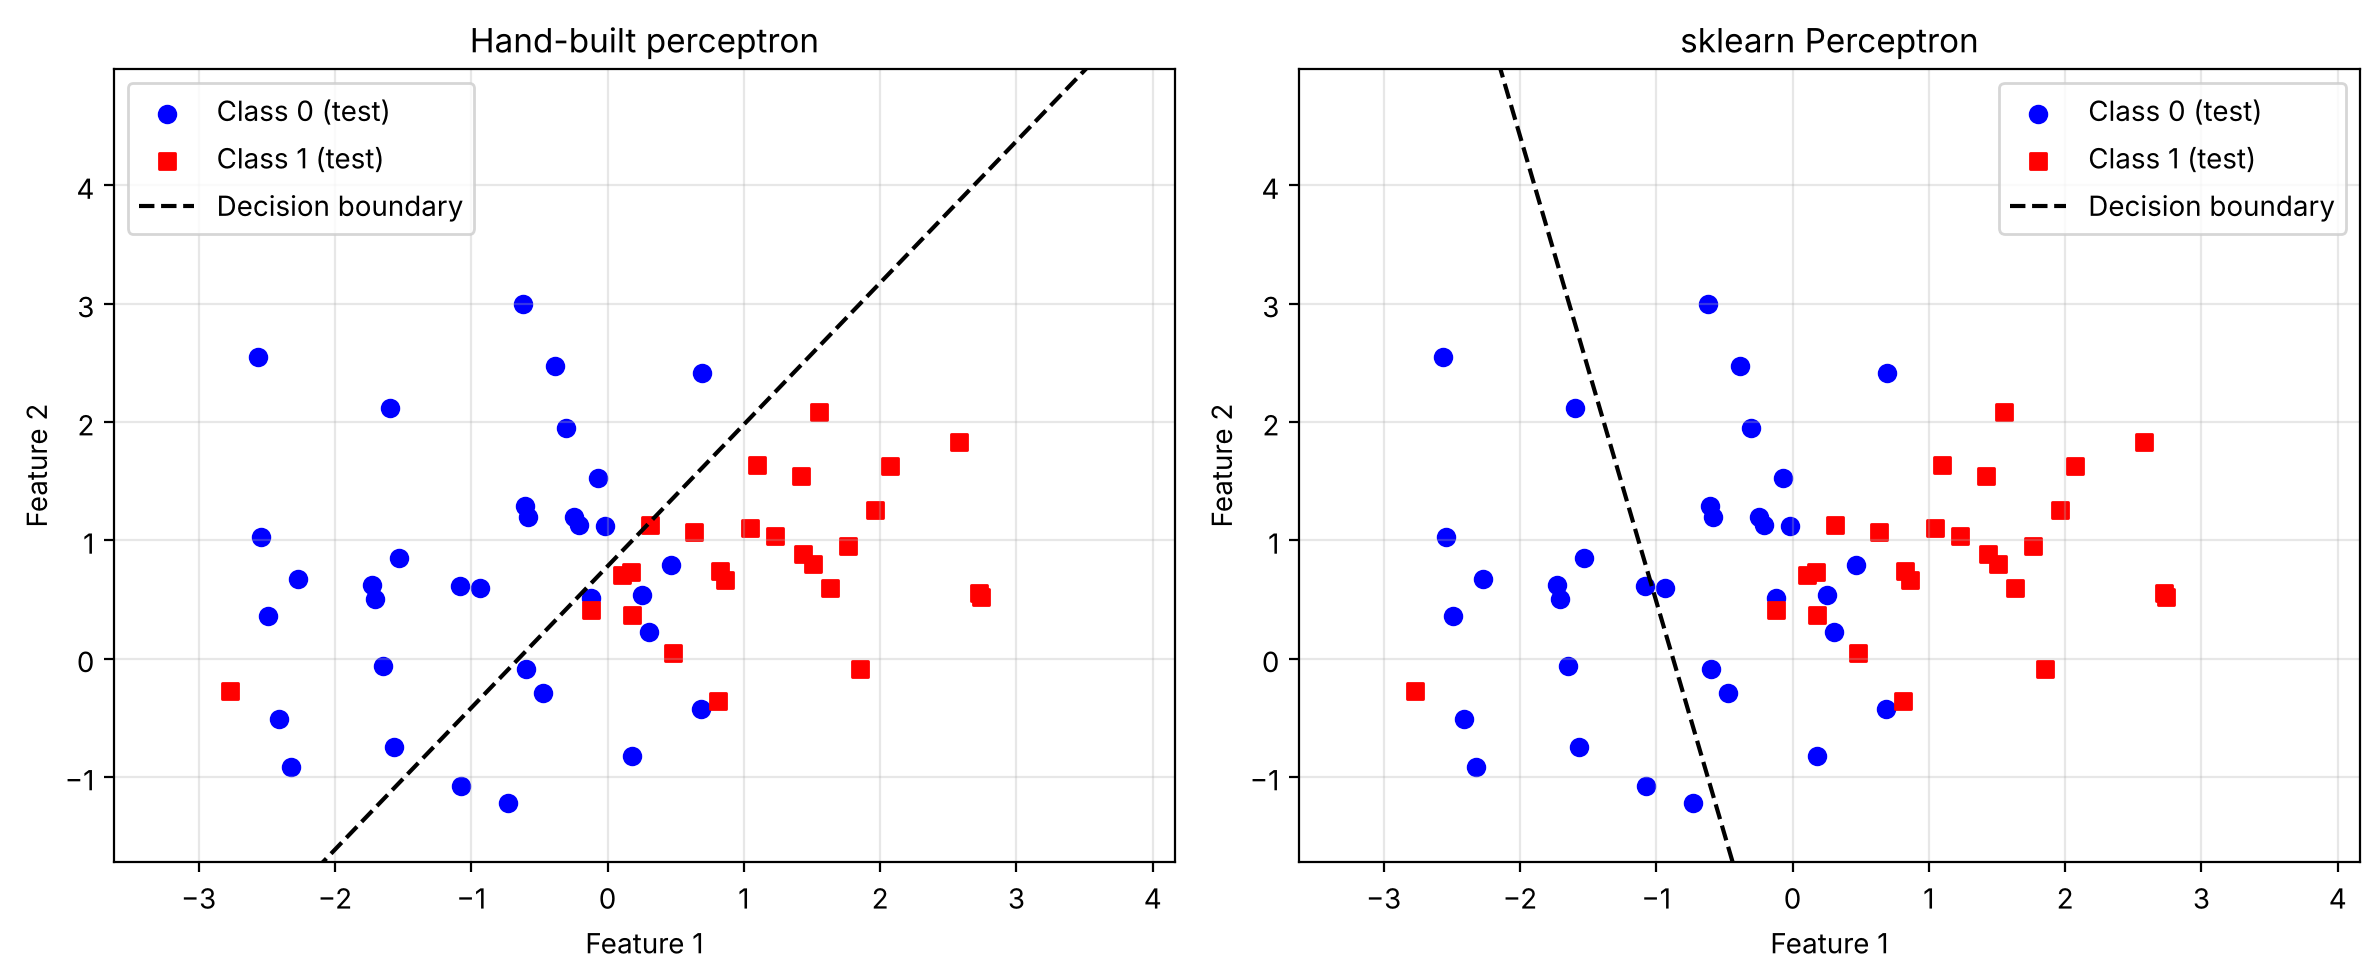

In [17]:
# Q5
Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=42)

w_h, b_h, m_h = train_perceptron(Xs_tr, ys_tr, eta=0.1, max_epochs=100)
pred_h = np.array([predict(w_h, x, b_h) for x in Xs_te])

sk = Perceptron(random_state=42, eta0=0.1).fit(Xs_tr, ys_tr)
pred_sk = sk.predict(Xs_te)

print(f"{'Model':<14} | {'Test acc':>8} | {'Epochs':>6} | {'w':<24} | b")
print("-" * 75)
print(f"{'Hand-built':<14} | {accuracy_score(ys_te, pred_h):>8.3f} | {len(m_h):>6} | {str(np.round(w_h, 3)):<24} | {b_h:.3f}")
print(f"{'sklearn':<14} | {accuracy_score(ys_te, pred_sk):>8.3f} | {sk.n_iter_:>6} | {str(np.round(sk.coef_[0], 3)):<24} | {sk.intercept_[0]:.3f}")
print("Hand-built final-epoch mistakes:", m_h[-1])

xl = (Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5)
yl = (Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, title, w_, b_ in [(axes[0], "Hand-built perceptron", w_h, b_h),
                          (axes[1], "sklearn Perceptron", sk.coef_[0], sk.intercept_[0])]:
    ax.scatter(*Xs_te[ys_te == 0].T, c="blue", marker="o", label="Class 0 (test)")
    ax.scatter(*Xs_te[ys_te == 1].T, c="red", marker="s", label="Class 1 (test)")
    plot_boundary(ax, w_, b_, xlim=xl)
    ax.set_xlim(xl)
    ax.set_ylim(yl)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Analysis:**

| Model | Test accuracy | Epochs | w | b |
|---|---|---|---|---|
| Hand-built | 0.817 | 100 (max, did not converge) | [0.307, −0.256] | 0.200 |
| scikit-learn | 0.667 | 6 | [0.228, 0.058] | 0.200 |

This synthetic data has overlapping classes, so it is not linearly separable. The hand-built perceptron never reaches a zero-mistake epoch and runs all 100 epochs (33 training mistakes in the last one), and its final boundary is just the weights from wherever training stopped. scikit-learn's perceptron stops after only 6 epochs by its own stopping rule and ends with a worse boundary (see the plots), so on this particular test split the hand-built model scores higher. Neither result is reliable, since the perceptron has no convergence guarantee here; the difference mostly reflects where the updates happened to stop.